In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.tree import plot_tree

# 设置中文显示
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False


In [2]:
# 加载鸢尾花数据集
iris = datasets.load_iris()
X = iris.data
y = iris.target

# 划分数据集为训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(105, 4) (45, 4) (105,) (45,)


## 数据探索：特征相关性

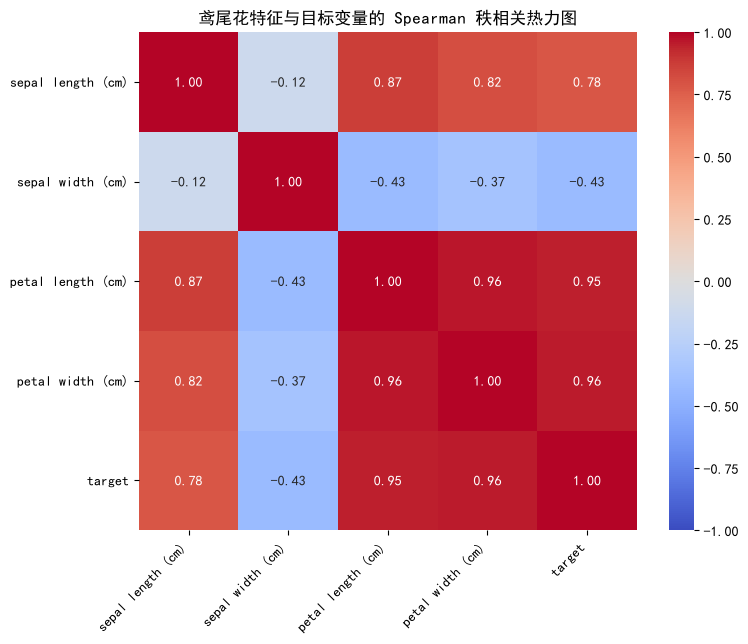

In [3]:
import pandas as pd
import seaborn as sns

# 转成 DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target

plt.figure(figsize=(8, 6.5))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('鸢尾花特征与目标变量的 Spearman 秩相关热力图')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 决策树模型应用

In [4]:
# 创建并训练决策树模型
from sklearn.tree import DecisionTreeClassifier

# 设置显示模式为文本
from sklearn import set_config
set_config(display='text')

decision_tree_model = DecisionTreeClassifier(random_state=42)
decision_tree_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [5]:
# 预测测试数据
y_pred = decision_tree_model.predict(X_test)

# 计算准确度
accuracy = accuracy_score(y_test, y_pred)

# 生成混淆矩阵
conf_matrix = confusion_matrix(y_test, y_pred)

# 打印分类报告
class_report = classification_report(y_test, y_pred, target_names=iris.target_names)

# 打印模型评估结果
print(f"准确率 Accuracy: {accuracy:.2f}\n")
print(f"混淆矩阵 Confusion Matrix:\n{conf_matrix}\n")
print(f"分类报告 Classification Report:\n{class_report}")

准确率 Accuracy: 1.00

混淆矩阵 Confusion Matrix:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]

分类报告 Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



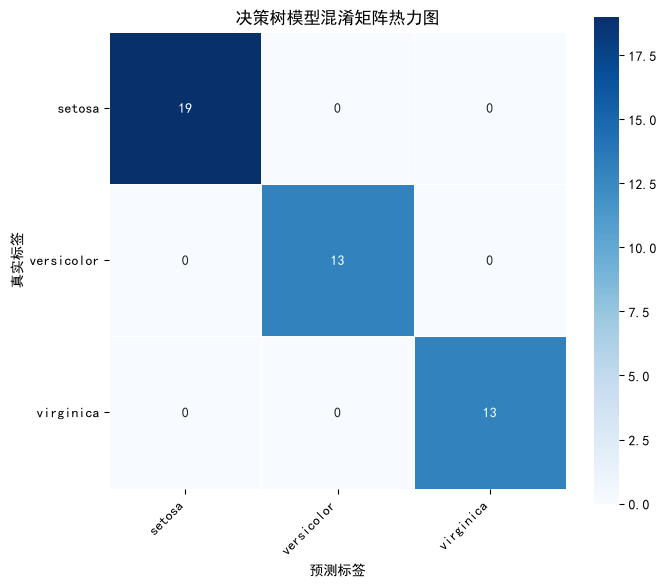

In [6]:
# 决策树混淆矩阵热力图（seaborn）
import seaborn as sns

cm_dt = confusion_matrix(y_test, decision_tree_model.predict(X_test))

plt.figure(figsize=(7, 6))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names,
            square=True, linewidths=0.5)
plt.title('决策树模型混淆矩阵热力图')
plt.xlabel('预测标签')
plt.ylabel('真实标签')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


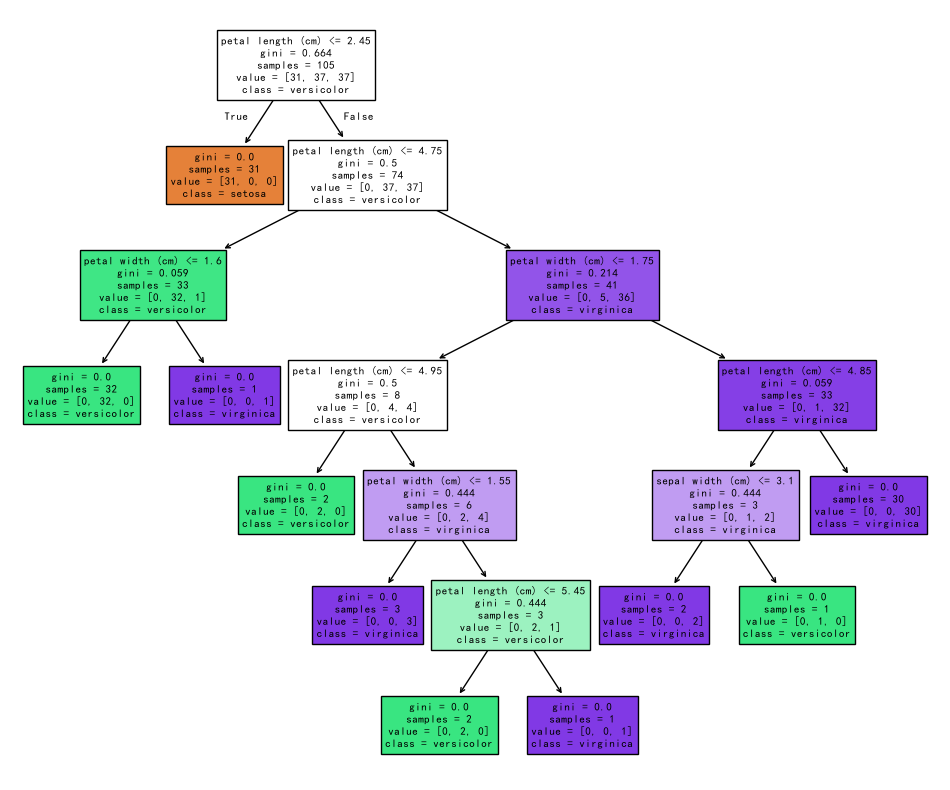

In [7]:
# 绘制决策树
plt.figure(figsize=(12, 10))
plot_tree(decision_tree_model, filled=True, feature_names=iris.feature_names, class_names=iris.target_names.tolist())
plt.show()

## 随机森林模型应用

In [8]:
# 创建并训练随机森林模型
from sklearn.ensemble import RandomForestClassifier
random_forest_model = RandomForestClassifier(n_estimators=100, random_state=42)
random_forest_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [9]:
# 预测测试数据
y_pred = random_forest_model.predict(X_test)

# 计算准确度
accuracy = accuracy_score(y_test, y_pred)

# 生成混淆矩阵
conf_matrix = confusion_matrix(y_test, y_pred)

# 打印分类报告
class_report = classification_report(y_test, y_pred, target_names=iris.target_names)

# 打印模型评估结果
print(f"准确率 Accuracy: {accuracy:.2f}")
print(f"混淆矩阵 Confusion Matrix:\n{conf_matrix}")
print(f"分类报告 Classification Report:\n{class_report}")

准确率 Accuracy: 1.00
混淆矩阵 Confusion Matrix:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
分类报告 Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



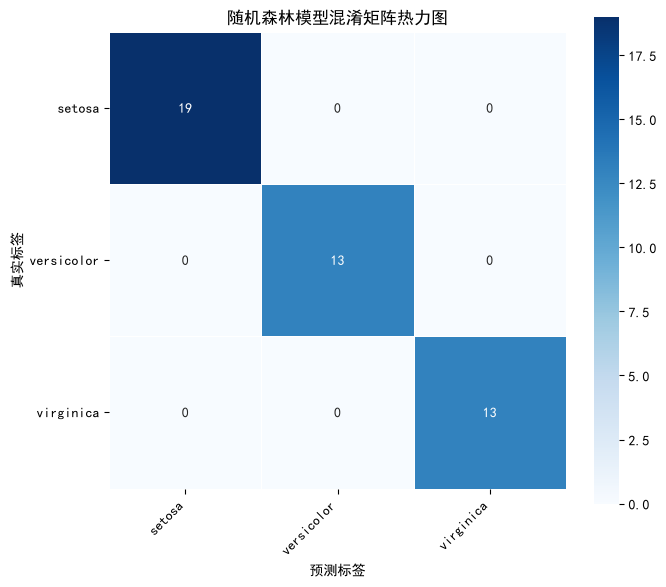

In [10]:
# 随机森林混淆矩阵热力图（seaborn）
import seaborn as sns

cm_rf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names,
            square=True, linewidths=0.5)
plt.title('随机森林模型混淆矩阵热力图')
plt.xlabel('预测标签')
plt.ylabel('真实标签')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

特征的重要性：
{'sepal length (cm)': 0.1041, 'sepal width (cm)': 0.0446, 'petal length (cm)': 0.4173, 'petal width (cm)': 0.434}


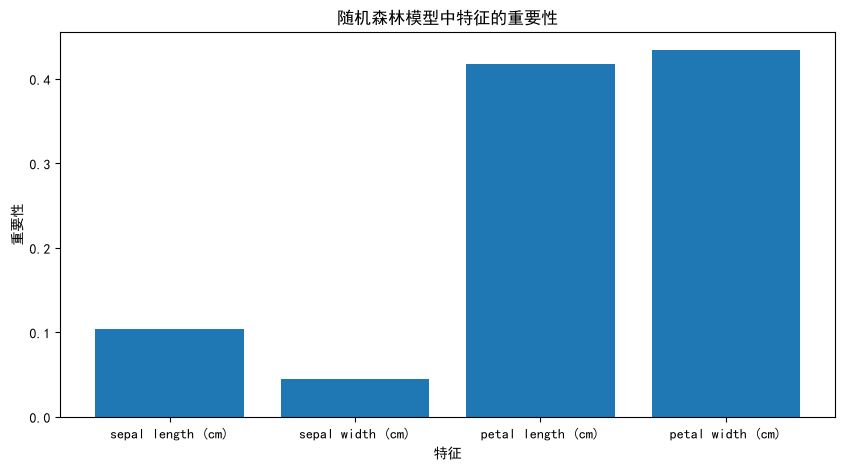

In [11]:
# 特征的重要性
feature_importance = random_forest_model.feature_importances_
print("特征的重要性：")
print(dict(zip(iris.feature_names, np.round(feature_importance, 4))))

# 可视化特征的重要性
plt.figure(figsize=(10, 5))
plt.bar(iris.feature_names, feature_importance)
plt.xlabel('特征')
plt.ylabel('重要性')
plt.title('随机森林模型中特征的重要性')
plt.show()

## 朴素贝叶斯模型应用

In [12]:
from sklearn.naive_bayes import GaussianNB
# 创建朴素贝叶斯分类器
model = GaussianNB()

# 训练模型
model.fit(X_train, y_train)

# 进行预测
y_pred = model.predict(X_test)

In [13]:
# 评估模型性能
accuracy = accuracy_score(y_test, y_pred)
confusion = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred, target_names=iris.target_names)

print(f"准确率 Accuracy: {accuracy:.2f}")
print("混淆矩阵 Confusion Matrix:\n", confusion)
print("分类报告 Classification Report:\n", report)


准确率 Accuracy: 0.98
混淆矩阵 Confusion Matrix:
 [[19  0  0]
 [ 0 12  1]
 [ 0  0 13]]
分类报告 Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      0.92      0.96        13
   virginica       0.93      1.00      0.96        13

    accuracy                           0.98        45
   macro avg       0.98      0.97      0.97        45
weighted avg       0.98      0.98      0.98        45



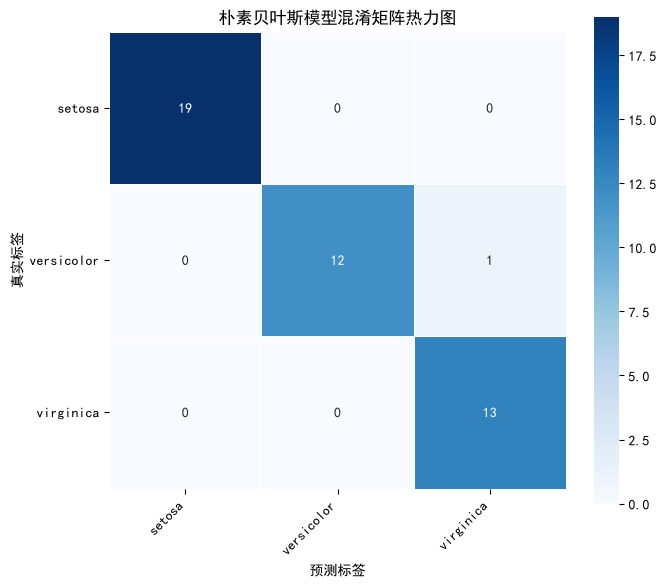

In [14]:
# 朴素贝叶斯混淆矩阵热力图（seaborn）
import seaborn as sns

plt.figure(figsize=(7, 6))
sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names,
            square=True, linewidths=0.5)
plt.title('朴素贝叶斯模型混淆矩阵热力图')
plt.xlabel('预测标签')
plt.ylabel('真实标签')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 观察实验现象

1. **决策树可视化图**：根节点以“花瓣长 ≤ 2.45 cm”一次分出 setosa（105 个训练样本中占 31 个，基尼系数降为 0）；其余样本按“花瓣长 ≤ 4.75 cm”，再用“花瓣宽 ≤ 1.60 cm / 1.75 cm”逐层划分 versicolor 与 virginica，后几层才引入萼片宽、萼片长区分重叠样本。整棵树最大深度 6、共 10 个叶节点，分裂准则为默认的 gini 系数。

2. **随机森林特征重要性**：花瓣宽 0.4340、花瓣长 0.4173 两根柱子最高，萼片长 0.1041、萼片宽 0.0446 明显偏低，即花瓣尺寸两个特征合计贡献约 85%，是分类的主要依据，该排序与前面相关性分析的结论一致。

3. **混淆矩阵**：决策树与随机森林对角线为 19、13、13，45 个测试样本全部分对，非对角线全为 0；高斯朴素贝叶斯对角线为 19、12、13，仅在“真实 versicolor、预测 virginica”处有 1 个错分，准确率 0.98。

4. **三模型对比**：测试准确率决策树 1.00、随机森林 1.00、高斯朴素贝叶斯 0.98；两个树模型的精确率、召回率、F1 全为 1.00，朴素贝叶斯 versicolor 召回率 0.92、virginica 精确率 0.93，macro F1 为 0.97。三个模型对 setosa 均 19/19 全对，差异只出现在 versicolor 与 virginica 的重叠区。
